In [1]:
#%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import config
import general
import contraction
import constantes
import profiles

import pandas as pd

from scipy.integrate import quad

In [2]:
plt.rcParams['axes.labelsize'] = 20  
plt.rcParams['xtick.labelsize'] = 18   
plt.rcParams['ytick.labelsize'] = 18

XLIM = (20, 210)
YLIM = (1e-6, 1e-1)
FIGSIZE = (10,10)

In [3]:
halo = general.contract_halo()

# Convert the simulated radius from Mpc/h back to physical kpc
r_kpc_sim = (halo['r'] / constantes.H) * 1000.0
rf_kpc_sim = (halo['r_f'] / constantes.H) * 1000.0

dm = halo['dm_profile']
bar = halo['baryon_profile']
cnt = halo['contraction']
rho_baryons = halo['rho_stars'] + halo['rho_gas']

# Calculate Abell 1703 Observational Truth [20 - 210 kpc]
r_s_kpc = 727.0
alpha = 1.09
c200 = 3.1
r_cut_cd_kpc = 30.0 
sigma_0_cd = 299.4
G_kpc = 4.30091e-6

r_kpc_obs = np.linspace(20, 210, 500)

# Normalizations
rho_0_dpie_kpc = (sigma_0_cd**2) / (2 * np.pi * G_kpc)

def gnfw_integrand(x, alpha_val):
    return (x**2) / ((x**alpha_val) * (1 + x)**(3 - alpha_val))

integral_val, _ = quad(gnfw_integrand, 0, c200, args=(alpha,))

z_cluster = 0.28
H0 = 70.0
Omega_m = 0.3
Omega_L = 0.7

Hz_kpc = (H0 / 1000.0) * np.sqrt(Omega_m * (1 + z_cluster)**3 + Omega_L)
rho_crit_z = (3 * Hz_kpc**2) / (8 * np.pi * G_kpc)
rho_s_kpc = (200.0 / 3.0) * rho_crit_z * (c200**3) / integral_val

density_cd_pc = (rho_0_dpie_kpc / ((r_kpc_obs**2) * (1 + (r_kpc_obs / r_cut_cd_kpc)**2))) / 1e9
x = r_kpc_obs / r_s_kpc
density_gnfw_pc = (rho_s_kpc / ((x**alpha) * (1 + x)**(3 - alpha))) / 1e9

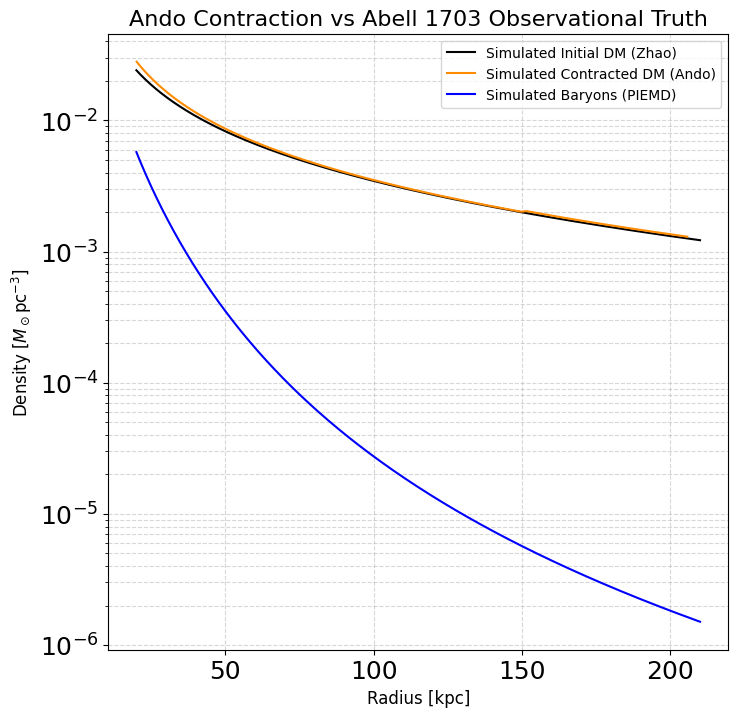

In [4]:
FIGSIZE = (8,8)
plt.figure(figsize=FIGSIZE)

# Plot Simulated Profiles
plt.semilogy(r_kpc_sim, halo['rho_dm_initial'] , label=f'Simulated Initial DM ({dm})', color='black')

# 1. Slice off the artificial first point (index 0) from the contracted arrays
rf_clean = rf_kpc_sim[1:]
rho_contracted_clean = halo['rho_dm_contracted'][1:]

# 2. Apply the mask to the cleaned arrays
valid_rf = rf_clean >= 20

# 3. Plot the cleaned, masked arrays
plt.semilogy(rf_clean[valid_rf], rho_contracted_clean[valid_rf] , label=f'Simulated Contracted DM ({cnt})', color='darkorange')

plt.semilogy(r_kpc_sim, rho_baryons , label=f'Simulated Baryons ({bar})', color='blue')

# Plot Observational Truth (Abell 1703) on absolute kpc scale
# plt.semilogy(r_kpc_obs, density_gnfw_pc, label=f'Abell 1703 DM (gNFW, $\\alpha$={alpha})', color='purple', ls='--', linewidth=2.5)
# plt.semilogy(r_kpc_obs, density_cd_pc, label=f'Abell 1703 Baryons (cD Galaxy)', color='magenta', ls='--', linewidth=2.5)

plt.title(f"{cnt.capitalize()} Contraction vs Abell 1703 Observational Truth", fontsize=16)
plt.xlabel(r'Radius [kpc]', fontsize=12)
plt.ylabel(r'Density [$M_\odot \mathrm{pc}^{-3}$]', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, which="both", ls="--", alpha=0.5)

plt.show()

### Contrairement au stage il n'y a pas de croisement car ce ne sont pas les mêmes masses de halos et densité 

In [5]:
print (40 * 0.7)

28.0
